# GameTheory-09d : Stackelberg PPO — quand le concepteur anticipe l'adaptation du contrôleur

**Navigation** : [GameTheory-09b — engagement et Stackelberg](./GameTheory-09b-Commitment-Stackelberg-Python.ipynb) · [GameTheory-09c — security game](./GameTheory-09c-Stackelberg-SecurityGame-Python.ipynb) · [RL-06c — PPO depuis zéro](../RL/RL-06c-PPO-Depuis-Zero-Python.ipynb) · [Sommaire GameTheory](./README.md)

## Pourquoi ce notebook

GT-9b a posé l'idée de Stackelberg sur des jeux finis : le leader s'engage **parce qu'il sait** comment l'autre va répondre. Ce carnet suit la même idée dans un cadre où personne ne connaît la meilleure réponse en forme close : un **concepteur** (le leader) choisit le corps d'un robot, un **contrôleur** (le suiveur) apprend à s'en servir par renforcement.

La source est Dai, Wang, Ashley et Schmidhuber, *Efficient Morphology-Control Co-Design via Stackelberg Proximal Policy Optimization*, ICLR 2026 (arXiv:2603.15388). Le papier a été lu en entier, annexes comprises. Copie hors dépôt : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\2026 - Dai et al - Bilevel Morphology Co-Design.pdf`.

Le constat de départ du papier (introduction) : les méthodes de co-design mettent à jour la morphologie **en tenant le contrôleur pour fixe**. Or le contrôleur va s'adapter au nouveau corps. Le concepteur optimise donc contre un partenaire qui n'existera plus au pas suivant.

## Ce qu'on vérifie

Le papier fait des affirmations qu'on peut confronter à une mesure, à petite échelle et sur CPU :

| Affirmation (section du papier) | Où dans ce carnet |
|---|---|
| Le gradient du leader a un terme **indirect** qui passe par la réponse du suiveur (éq. 2-3) | §1, duopole de Cournot |
| La régularisation $\lambda$ interpole entre le gradient de Stackelberg ($\lambda \to 0$) et le gradient ordinaire ($\lambda \to \infty$) (éq. 10, fig. 4b) | §1, balayage de $\lambda$ contre une forme close |
| Le théorème 1 : un estimateur par rapports de vraisemblance donne la dérivée croisée **sans dériver à travers l'interface** | §2, comparaison avec la valeur exacte |
| Stackelberg PPO fait mieux que le PPO ordinaire en co-design (+20,66 % en moyenne annoncés) | §3, co-design à interface discrète, 4 graines |
| Les performances restent robustes pour $\lambda \in [0{,}5 ; 10]$ et se dégradent aux extrêmes (fig. 4b) | §3, balayage de $\lambda$ |

Les expériences du papier tournent sur MuJoCo pendant environ 30 h par modèle sur un GPU A100 (annexe D.1). Ici, chaque mesure prend quelques secondes : le carnet garde **la structure** du problème (deux phases, interface non dérivable, suiveur PPO), pas son échelle.

## 0. Mise en place

La référence analytique du duopole vient du module du dépôt `examples/stackelberg_leader_follower.py`, déjà couvert par `tests/test_stackelberg.py` (Cournot (30, 30) et Stackelberg (45 ; 22,5) pour $a = 100$, $c = 10$). Le carnet l'appelle au lieu de recalculer ces équilibres.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from examples.stackelberg_leader_follower import cournot_equilibrium, stackelberg_equilibrium
# le module fixe le backend Agg a l'import (usage script) : on retablit l'affichage inline
%matplotlib inline

torch.set_default_dtype(torch.float64)
SEEDS = [0, 1, 7, 42]
A_DEM, C_MARG = 100.0, 10.0

qC = cournot_equilibrium(A_DEM, C_MARG)
qS = stackelberg_equilibrium(A_DEM, C_MARG, C_MARG)
print(f"PyTorch {torch.__version__}, numpy {np.__version__}")
print(f"Organe du depot -- Cournot (Nash simultane) : q = {qC}")
print(f"Organe du depot -- Stackelberg (leader engage) : (q_L, q_F) = {qS}")

PyTorch 2.14.0+cu126, numpy 2.4.6
Organe du depot -- Cournot (Nash simultane) : q = (30.0, 30.0)
Organe du depot -- Stackelberg (leader engage) : (q_L, q_F) = (45.0, 22.5)


## 1. Le terme indirect du gradient, sur un duopole

Deux entreprises choisissent leurs quantités $q_L$ et $q_F$ ; le prix vaut $a - q_L - q_F$ et le coût marginal $c$. Les profits sont $J_L = (a - q_L - q_F - c)\,q_L$ et $J_F = (a - q_L - q_F - c)\,q_F$.

Le papier écrit le gradient de Stackelberg du leader (éq. 2) :

$$\nabla_{\theta_L} J_L\big(\theta_L, \theta_F^*(\theta_L)\big) = \underbrace{\nabla_{\theta_L} J_L}_{\text{direct}} + \underbrace{\big(\nabla_{\theta_L}\theta_F^*\big)^\top \nabla_{\theta_F} J_L}_{\text{indirect}}$$

La jacobienne de la réponse sort de la condition du premier ordre du suiveur, $\nabla_{\theta_F} J_F = 0$, par le théorème des fonctions implicites (éq. 3) :

$$\big(\nabla_{\theta_L}\theta_F^*\big)^\top = -\nabla_{\theta_L \theta_F} J_F \,\big(\nabla^2_{\theta_F} J_F\big)^{-1}.$$

Le papier remplace ensuite $-\nabla^2_{\theta_F} J_F$ (négative, puisque le suiveur maximise) par une matrice positive régularisée, $F + \lambda I$. On fait la même chose ici avec la hessienne exacte : $(-\nabla^2_{\theta_F} J_F + \lambda)^{-1}$. Avec $\lambda = \infty$, le terme indirect disparaît : c'est le gradient « ordinaire » du papier, celui qui tient le suiveur pour fixe.

**Point de convention.** L'éq. 10 du papier et son annexe D.3 écrivent le terme indirect avec un signe moins, parce que leurs surrogates y apparaissent comme des pertes. Avec des objectifs à **maximiser** et une matrice positive à la place de $-\nabla^2 J_F$, le terme entre avec un signe plus. Le duopole tranche la question : seul le bon signe peut ramener l'équilibre de Stackelberg (45 ; 22,5).

Les deux joueurs montent leur gradient en même temps, le suiveur dix fois plus vite (il « s'adapte »), le leader avec le gradient régularisé.

In [2]:
def J_L(qL, qF):
    return (A_DEM - qL - qF - C_MARG) * qL

def J_F(qL, qF):
    return (A_DEM - qL - qF - C_MARG) * qF

def leader_gradient(qL, qF, lam):
    # gradient du leader = direct + indirect (eq. 2-3), hessienne regularisee par lam
    qL = qL.clone().requires_grad_(True)
    qF = qF.clone().requires_grad_(True)
    g_dir, gF_JL = torch.autograd.grad(J_L(qL, qF), (qL, qF))
    if np.isinf(lam):
        return g_dir
    gF_JF, = torch.autograd.grad(J_F(qL, qF), qF, create_graph=True)
    H, = torch.autograd.grad(gF_JF, qF, retain_graph=True)       # d2 J_F / d qF2 < 0
    v = gF_JL / (-H + lam)                                       # (-H + lam)^-1 grad_F J_L
    cross, = torch.autograd.grad(gF_JF, qL, grad_outputs=v.detach())
    return g_dir + cross

def run_duopole(lam, steps=4000, lr_L=0.02, lr_F=0.2):
    qL, qF = torch.tensor(10.0), torch.tensor(10.0)
    for _ in range(steps):
        gL = leader_gradient(qL, qF, lam)
        qF_ = qF.clone().requires_grad_(True)
        gF, = torch.autograd.grad(J_F(qL, qF_), qF_)
        qL, qF = qL + lr_L * gL, qF + lr_F * gF
    return qL.item(), qF.item()

def qL_closed_form(lam):
    # point fixe : (a-c)/2 - 1.5 qL + qL/(2+lam) = 0 (suiveur sur sa courbe de reaction)
    corr = 0.0 if np.isinf(lam) else 1.0 / (2.0 + lam)
    return (A_DEM - C_MARG) / 2 / (1.5 - corr)

LAMBDAS = [0.0, 0.5, 1.0, 5.0, 10.0, np.inf]
duo = {}
print(f"{'lambda':>7} | {'q_L simule':>10} | {'q_F simule':>10} | {'q_L forme close':>15} | ecart")
for lam in LAMBDAS:
    qL, qF = run_duopole(lam)
    th = qL_closed_form(lam)
    duo[lam] = (qL, qF, th)
    print(f"{lam:>7} | {qL:10.4f} | {qF:10.4f} | {th:15.4f} | {abs(qL - th):.1e}")
print(f"\nlambda=0  -> Stackelberg de l'organe {qS} : ecart q_L = {abs(duo[0.0][0] - qS[0]):.1e}")
print(f"lambda=inf -> Cournot de l'organe {qC}    : ecart q_L = {abs(duo[np.inf][0] - qC[0]):.1e}")

 lambda | q_L simule | q_F simule | q_L forme close | ecart


    0.0 |    45.0000 |    22.5000 |         45.0000 | 1.8e-13


    0.5 |    40.9091 |    24.5455 |         40.9091 | 1.6e-13


    1.0 |    38.5714 |    25.7143 |         38.5714 | 1.5e-13


    5.0 |    33.1579 |    28.4211 |         33.1579 | 1.2e-13


   10.0 |    31.7647 |    29.1176 |         31.7647 | 5.7e-14


    inf |    30.0000 |    30.0000 |         30.0000 | 5.7e-14

lambda=0  -> Stackelberg de l'organe (45.0, 22.5) : ecart q_L = 1.8e-13
lambda=inf -> Cournot de l'organe (30.0, 30.0)    : ecart q_L = 5.7e-14


### Lecture du résultat

La montée de gradient retrouve la forme close à $10^{-13}$ près pour les six valeurs de $\lambda$. Aux deux extrémités, elle retombe exactement sur les équilibres calculés par l'organe du dépôt : $\lambda = 0$ donne (45 ; 22,5), l'équilibre de Stackelberg, et $\lambda = \infty$ donne (30 ; 30), l'équilibre de Cournot. Le signe plus du terme indirect est donc le bon. Avec le signe moins de l'éq. 10 recopié tel quel, le même calcul donnerait $q_L = 45 / (1{,}5 + 1/(2 + \lambda))$, soit 22,5 pour $\lambda = 0$ : le leader produirait moins qu'à l'équilibre de Cournot au lieu de s'engager davantage.

Entre les deux, $\lambda$ règle la part du déplacement Cournot → Stackelberg que le leader capture : $(40{,}91 - 30)/15 = 73\,\%$ pour $\lambda = 0{,}5$, $57\,\%$ pour $\lambda = 1$, mais seulement $21\,\%$ pour $\lambda = 5$ (la valeur du papier) et $12\,\%$ pour $\lambda = 10$. Ici la courbure du suiveur vaut $|\partial^2 J_F / \partial q_F^2| = 2$, et le facteur $1/(2 + \lambda)$ de la forme close montre que **$\lambda$ n'a de sens que rapporté à cette courbure**. Une même valeur numérique de $\lambda$ ne régularise pas de la même façon un problème où la courbure vaut 2 et un réseau dont la matrice de Fisher a de grandes valeurs propres.

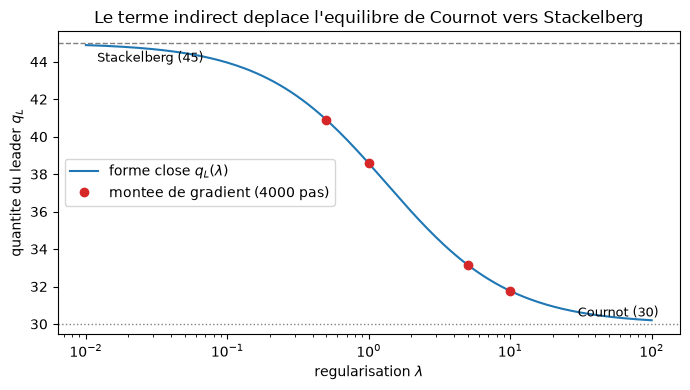

In [3]:
lam_grid = np.logspace(-2, 2, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(lam_grid, [qL_closed_form(l) for l in lam_grid], color="tab:blue", label="forme close $q_L(\\lambda)$")
finite = [l for l in LAMBDAS if 0 < l < np.inf]
ax.semilogx(finite, [duo[l][0] for l in finite], "o", color="tab:red", label="montee de gradient (4000 pas)")
ax.axhline(qS[0], ls="--", color="gray", lw=1)
ax.axhline(qC[0], ls=":", color="gray", lw=1)
ax.text(0.012, qS[0] - 1.0, "Stackelberg (45)", fontsize=9)
ax.text(30, qC[0] + 0.4, "Cournot (30)", fontsize=9)
ax.set_xlabel("regularisation $\\lambda$")
ax.set_ylabel("quantite du leader $q_L$")
ax.set_title("Le terme indirect deplace l'equilibre de Cournot vers Stackelberg")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

### Lecture de la figure

La courbe est monotone : diminuer $\lambda$ fait toujours avancer le leader vers 45. Elle est raide entre $\lambda = 0{,}5$ et $\lambda = 5$, c'est-à-dire autour de la courbure du suiveur ; en dessous de $10^{-1}$ et au-dessus de $10^{1}$, elle est presque plate.

## 2. Théorème 1 : la dérivée croisée sans dériver à travers l'interface

Dans le co-design, le leader n'agit pas sur le suiveur par une quantité continue. Il produit un **corps**, ici un nombre de segments $k \in \{1, \dots, 6\}$, tiré d'une politique catégorielle $\pi_L(k) = \mathrm{softmax}(\theta_L)_k$. Le suiveur ne voit que ce corps tiré au sort. On ne peut pas dériver $k$ par rapport à $\theta_L$ : c'est l'**interface non dérivable** du papier (introduction), que l'on franchit par l'astuce de la log-dérivée.

Le suiveur choisit une commande $a \sim \mathcal{N}(w, \sigma_F^2)$, et le corps rapporte $r_F = k\,a - a^2/2$ (vitesse moins effort). Son objectif a une forme close :

$$J_F(\theta_L, w) = w\,\mathbb{E}_{\pi_L}[k] - \frac{w^2 + \sigma_F^2}{2},$$

d'où la dérivée croisée exacte $\nabla_{\theta_L}\partial_w J_F = \nabla_{\theta_L}\mathbb{E}_{\pi_L}[k]$.

Le théorème 1 du papier propose un surrogate qui n'utilise que des échantillons et des rapports de probabilités (éq. 7) :

$$L^F_{L,F} = \mathbb{E}\Big[\frac{\pi_L(k)}{\pi_{L,o}(k)}\,\frac{\pi_F(a)}{\pi_{F,o}(a)}\,\hat A_F\Big],$$

et affirme qu'au point de collecte, sa dérivée croisée égale celle de $J_F$. On le vérifie : on estime la dérivée croisée sur $N$ échantillons, 4 graines, et on la compare à la valeur exacte. Ici $T = 1$ et l'horizon du suiveur vaut 1, donc $\gamma^T = 1$ et la constante $c$ du théorème se réduit à 1.

In [4]:
K = torch.arange(1, 7, dtype=torch.float64)   # morphologies possibles : 1 a 6 segments
COST = 0.25                                   # cout de materiau, r_L = -COST k^3 / 3
SIG_F = 1.0                                   # ecart-type de la commande du suiveur

def leader_dist(theta_L):
    return torch.distributions.Categorical(logits=theta_L)

def follower_dist(w):
    return torch.distributions.Normal(w, SIG_F)

def exact_JF(theta_L, w):
    Ek = (torch.softmax(theta_L, 0) * K).sum()
    return w * Ek - (w ** 2 + SIG_F ** 2) / 2

def sample(theta_L, w, n, gen):
    k_idx = torch.multinomial(torch.softmax(theta_L, 0).detach(), n, replacement=True, generator=gen)
    k = K[k_idx]
    a = w.detach() + SIG_F * torch.randn(n, generator=gen)
    return k_idx, k, a, k * a - a ** 2 / 2, -COST * k ** 3 / 3

def surrogates(theta_L, w, theta_Lo, w_o, k_idx, a, rF, rL):
    ratio_L = torch.exp(leader_dist(theta_L).log_prob(k_idx) - leader_dist(theta_Lo).log_prob(k_idx))
    ratio_F = torch.exp(follower_dist(w).log_prob(a) - follower_dist(w_o).log_prob(a))
    A_F = rF - rF.mean()
    A_L = (rL + rF) - (rL + rF).mean()
    L_LL = (ratio_L * A_L).mean()                  # eq. 8, gradient direct du leader
    L_LF = (ratio_F * A_F).mean()                  # eq. 8, gradient de J_L par rapport au suiveur
    L_FLF = (ratio_L * ratio_F * A_F).mean()       # eq. 7, theoreme 1
    kl = torch.distributions.kl_divergence(follower_dist(w_o), follower_dist(w)).mean()  # eq. 9
    return L_LL, L_LF, L_FLF, kl

theta_test = torch.tensor([0.5, 0.2, 0.0, -0.1, -0.3, -0.6])
w_test = torch.tensor(1.5)
tl, ww = theta_test.clone().requires_grad_(True), w_test.clone().requires_grad_(True)
gw, = torch.autograd.grad(exact_JF(tl, ww), ww, create_graph=True)
cross_exact, = torch.autograd.grad(gw, tl)
print("derivee croisee exacte :", np.round(cross_exact.numpy(), 4))

thm1 = {}
for n in [256, 1024, 4096, 16384]:
    errs = []
    for s in SEEDS:
        gen = torch.Generator().manual_seed(s)
        k_idx, k, a, rF, rL = sample(theta_test, w_test, n, gen)
        tl, ww = theta_test.clone().requires_grad_(True), w_test.clone().requires_grad_(True)
        _, _, L_FLF, _ = surrogates(tl, ww, theta_test, w_test, k_idx, a, rF, rL)
        gw, = torch.autograd.grad(L_FLF, ww, create_graph=True)
        est, = torch.autograd.grad(gw, tl)
        errs.append((est - cross_exact).norm().item() / cross_exact.norm().item())
    thm1[n] = errs
    print(f"N = {n:6d} : erreur relative par graine {np.round(errs, 3)}, mediane {np.median(errs):.3f}")
ratios = [np.median(thm1[n]) / np.median(thm1[4 * n]) for n in [256, 1024, 4096]]
print("rapport des medianes quand N est multiplie par 4 :", np.round(ratios, 2), "(1/sqrt(N) predit 2.0)")

derivee croisee exacte : [-0.5219 -0.1853  0.0132  0.1612  0.2541  0.2787]
N =    256 : erreur relative par graine [0.346 0.587 0.335 0.462], mediane 0.404
N =   1024 : erreur relative par graine [0.281 0.108 0.15  0.201], mediane 0.176
N =   4096 : erreur relative par graine [0.09  0.073 0.088 0.095], mediane 0.089
N =  16384 : erreur relative par graine [0.037 0.029 0.046 0.049], mediane 0.042
rapport des medianes quand N est multiplie par 4 : [2.3  1.98 2.14] (1/sqrt(N) predit 2.0)


### Lecture du résultat

L'estimateur du théorème 1 converge vers la dérivée croisée exacte sans jamais dériver à travers le tirage de $k$. Quand $N$ est multiplié par 4, l'erreur médiane est divisée par 2,30, puis 1,98, puis 2,14. C'est la décroissance en $1/\sqrt{N}$ d'un estimateur sans biais, et la médiane passe de 0,404 à 0,042.

Le chiffre qui compte pour la suite est celui de $N = 256$, la taille des lots de la section 3 : l'erreur relative y vaut 0,40 en médiane et va de 0,335 à 0,587 selon la graine. **Le terme indirect que reçoit le leader est donc bruité à environ 40 % à chaque itération.** C'est une des raisons du plafonnement de l'annexe D.3, qui empêche ce terme bruité de dominer le gradient direct.

## 3. Co-design à interface discrète : Stackelberg PPO contre PPO ordinaire

On assemble les deux phases du jeu de Stackelberg markovien séparé en phases (définition 1 du papier) :

1. **Phase leader** : le concepteur tire un corps $k \sim \pi_L$ et paie son coût de matériau $r_L = -c\,k^3/3$, avec $c = 0{,}25$.
2. **Phase suiveur** : le contrôleur commande ce corps et reçoit $r_F = k\,a - a^2/2$.

Le leader maximise $J_L = \mathbb{E}[r_L + r_F]$ (éq. 5), le suiveur seulement $J_F = \mathbb{E}[r_F]$ (éq. 6). Si le contrôleur était parfaitement adapté à un corps fixé, la commande optimale serait $a = k$ et la valeur du corps serait $k^2/2 - k^3/12 - 1/2$. Ce maximum est atteint en $k = 4$ ; c'est **l'optimum de Stackelberg** du concepteur.

Les deux joueurs apprennent sur les mêmes lots de 256 épisodes. À chaque itération :

- **le suiveur** fait 4 époques de PPO avec un surrogate clippé à $\epsilon = 0{,}2$, comme dans RL-06c ;
- **le leader** suit le gradient de l'éq. 10. La partie directe est $\nabla L^L_L$. La partie indirecte demande deux étapes : d'abord le gradient conjugué sur la hessienne du KL (éq. 9) régularisée par $\lambda$, ensuite un produit jacobienne-vecteur sur le surrogate du théorème 1.

On applique aussi la normalisation de l'annexe D.3 : la norme du terme indirect ne dépasse jamais celle du terme direct.

$\lambda = \infty$ correspond au gradient ordinaire, qui tient le contrôleur pour fixe. C'est la ligne de base du papier, BodyGen.

In [5]:
def conjugate_gradient(Avp, b, iters=10, tol=1e-3):
    x = torch.zeros_like(b)
    r, p = b.clone(), b.clone()
    rs = r @ r
    for _ in range(iters):
        Ap = Avp(p)
        alpha = rs / (p @ Ap)
        x, r = x + alpha * p, r - alpha * Ap
        rs_new = r @ r
        if rs_new.sqrt() < tol * b.norm():
            break
        p, rs = r + rs_new / rs * p, rs_new
    return x

def train_codesign(seed, lam, iters=300, n=256, lr_L=0.5, lr_F=0.05, ppo_epochs=4, eps=0.2):
    gen = torch.Generator().manual_seed(seed)
    theta_L, w = torch.zeros(6), torch.tensor(1.0)   # corps uniforme, controleur regle pour k=1
    hist = []
    for _ in range(iters):
        k_idx, k, a, rF, rL = sample(theta_L, w, n, gen)
        theta_Lo, w_o = theta_L.clone(), w.clone()
        tl, ww = theta_L.clone().requires_grad_(True), w.clone().requires_grad_(True)
        L_LL, L_LF, L_FLF, kl = surrogates(tl, ww, theta_Lo, w_o, k_idx, a, rF, rL)
        g_dir, = torch.autograd.grad(L_LL, tl, retain_graph=True)
        g_resp = torch.zeros_like(g_dir)
        if not np.isinf(lam):
            gF_LF, = torch.autograd.grad(L_LF, ww, retain_graph=True)
            gF_kl, = torch.autograd.grad(kl, ww, create_graph=True)
            def fisher_vp(v):
                hv, = torch.autograd.grad((gF_kl * v).sum(), ww, retain_graph=True)
                return hv.reshape(-1) + lam * v
            v = conjugate_gradient(fisher_vp, gF_LF.reshape(-1).detach())        # etape 1
            gF_FLF, = torch.autograd.grad(L_FLF, ww, create_graph=True)
            g_resp, = torch.autograd.grad((gF_FLF.reshape(-1) * v).sum(), tl)   # etape 2
        resp_norm = g_resp.norm().item()
        if resp_norm > 0:                                                        # annexe D.3
            g_resp = g_resp * min(1.0, g_dir.norm().item() / (resp_norm + 1e-8))
        theta_L = theta_L + lr_L * (g_dir + g_resp)
        # suiveur : PPO clippe sur le meme lot
        A_F = rF - rF.mean()
        wv = w_o.clone().requires_grad_(True)
        opt = torch.optim.SGD([wv], lr=lr_F)
        for _ in range(ppo_epochs):
            ratio = torch.exp(follower_dist(wv).log_prob(a) - follower_dist(w_o).log_prob(a))
            loss = -torch.min(ratio * A_F, ratio.clamp(1 - eps, 1 + eps) * A_F).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        w = wv.detach()
        p = torch.softmax(theta_L, 0)
        J_true = (p * (-COST * K ** 3 / 3)).sum().item() + exact_JF(theta_L, w).item()
        hist.append((float((p * K).sum()), w.item(), J_true, resp_norm, p[3].item()))
    return np.array(hist)

LAMBDAS_CD = [np.inf, 10.0, 5.0, 1.0, 0.5, 0.0]
t0 = time.time()
runs = {lam: {s: train_codesign(s, lam) for s in SEEDS} for lam in LAMBDAS_CD}
print(f"{len(LAMBDAS_CD) * len(SEEDS)} entrainements de 300 iterations en {time.time() - t0:.0f} s\n")

def first_hit(h, thr=0.9):
    idx = np.where(h[:, 4] >= thr)[0]
    return int(idx[0]) if len(idx) else None

print(f"{'lambda':>6} | {'E[k] final par graine':>26} | {'J_L final':>9} | P(k=4) >= 0.9 atteint a l'iteration")
for lam in LAMBDAS_CD:
    hs = [runs[lam][s] for s in SEEDS]
    ek = " ".join(f"{h[-1, 0]:.2f}" for h in hs)
    jl = np.median([h[-1, 2] for h in hs])
    hits = [first_hit(h) for h in hs]
    print(f"{lam:>6} | {ek:>26} | {jl:9.3f} | {hits}")

24 entrainements de 300 iterations en 59 s

lambda |      E[k] final par graine | J_L final | P(k=4) >= 0.9 atteint a l'iteration
   inf |        3.00 3.00 3.00 3.00 |     1.744 | [None, None, None, None]
  10.0 |        3.00 3.00 3.00 3.00 |     1.744 | [None, None, None, None]
   5.0 |        3.00 3.00 3.00 3.00 |     1.744 | [None, None, None, None]
   1.0 |        3.00 3.01 3.00 3.01 |     1.744 | [None, None, None, None]
   0.5 |        3.00 3.02 4.00 3.99 |     1.950 | [None, None, 31, 175]
   0.0 |        4.00 4.00 4.00 4.00 |     2.160 | [64, 30, 17, 20]


### Lecture du résultat

Les 24 entraînements (6 valeurs de $\lambda$ × 4 graines) prennent une minute environ sur CPU. Le résultat est tranché :

| $\lambda$ | corps final | $J_L$ final (médiane) | graines qui atteignent $P(k=4) \geq 0{,}9$ |
|---|---|---|---|
| $\infty$ (PPO ordinaire), 10, 5 | $E[k] = 3{,}00$ sur 4 graines | 1,744 | 0/4 |
| 1 | $E[k]$ de 3,00 à 3,01 | 1,744 | 0/4 |
| 0,5 | 3,00 ; 3,02 ; 4,00 ; 3,99 | 1,950 | 2/4 (itérations 31 et 175) |
| 0 | $E[k] = 4{,}00$ sur 4 graines | 2,160 | 4/4 (itérations 64, 30, 17, 20) |

Le PPO ordinaire ne se trompe pas « un peu » : il converge sur les quatre graines vers un corps à trois segments et ne le quitte plus. Le gain de Stackelberg PPO à $\lambda = 0$ vaut $2{,}160 / 1{,}744 - 1 = 24\,\%$ de récompense pour le concepteur. Ce chiffre ressemble aux $+20{,}66\,\%$ du papier, mais les deux ne se comparent pas : l'un mesure un problème jouet à une dimension, l'autre une moyenne sur les tâches MuJoCo du papier.

La section suivante explique pourquoi l'arrêt se fait précisément à $k = 3$.

### 3.1 Pourquoi le gradient ordinaire s'arrête à $k = 3$

Pour le comprendre, il suffit de regarder le jeu **simultané** : chaque joueur répond au comportement **actuel** de l'autre. On calcule la meilleure réponse du concepteur à un contrôleur réglé sur $w$, puis la meilleure réponse du contrôleur au corps $k$, et on cherche les points fixes. On compare ensuite avec l'optimum de Stackelberg, où le concepteur anticipe que le contrôleur s'adaptera.

In [6]:
def designer_value_fixed_controller(k, w):
    # concepteur qui tient le controleur pour fixe : r_L + E[r_F | k, w]
    return -COST * k ** 3 / 3 + k * w - (w ** 2 + SIG_F ** 2) / 2

def designer_value_adapted(k):
    # concepteur qui anticipe : le controleur s'adaptera a w = k
    return designer_value_fixed_controller(k, k)

ks = np.arange(1, 7)
print("Meilleure reponse du concepteur a un controleur fixe w (meilleur k) :")
for w in [1, 2, 3, 4, 5]:
    vals = [designer_value_fixed_controller(k, w) for k in ks]
    print(f"  w = {w} -> k = {ks[int(np.argmax(vals))]}   (valeurs {np.round(vals, 2)})")
print("Meilleure reponse du controleur a un corps k : w = k")
nash = [int(k) for k in ks if ks[int(np.argmax([designer_value_fixed_controller(kk, k) for kk in ks]))] == k]
print(f"\nPoints fixes du jeu simultane (Nash en strategies pures) : k = {nash}")
vals_adapt = [designer_value_adapted(k) for k in ks]
print(f"Valeur avec controleur adapte : {dict(zip(ks.tolist(), [round(float(v), 3) for v in vals_adapt]))}")
print(f"Optimum de Stackelberg : k = {int(ks[int(np.argmax(vals_adapt))])}")

Meilleure reponse du concepteur a un controleur fixe w (meilleur k) :
  w = 1 -> k = 2   (valeurs [ -0.08   0.33  -0.25  -2.33  -6.42 -13.  ])
  w = 2 -> k = 3   (valeurs [-0.58  0.83  1.25  0.17 -2.92 -8.5 ])
  w = 3 -> k = 3   (valeurs [-2.08  0.33  1.75  1.67 -0.42 -5.  ])
  w = 4 -> k = 4   (valeurs [-4.58 -1.17  1.25  2.17  1.08 -2.5 ])
  w = 5 -> k = 4   (valeurs [-8.08 -3.67 -0.25  1.67  1.58 -1.  ])
Meilleure reponse du controleur a un corps k : w = k

Points fixes du jeu simultane (Nash en strategies pures) : k = [3, 4]
Valeur avec controleur adapte : {1: -0.083, 2: 0.833, 3: 1.75, 4: 2.167, 5: 1.583, 6: -0.5}
Optimum de Stackelberg : k = 4


### Lecture du résultat

Le jeu simultané a **deux** équilibres de Nash en stratégies pures, $k = 3$ et $k = 4$. Face à un contrôleur réglé sur $w = 3$, un corps à trois segments rapporte 1,75 et un corps à quatre 1,67 : le concepteur qui tient le contrôleur pour fixe n'a aucune raison de grandir. Et le contrôleur, face à $k = 3$, reste sur $w = 3$. Le point (3, 3) est stable pour les deux.

Le gradient ordinaire part d'un contrôleur réglé sur $w = 1$ (meilleure réponse $k = 2$) et monte avec lui ; il s'arrête au **premier** point fixe rencontré, $k = 3$. Le concepteur qui anticipe l'adaptation compare autre chose : 1,75 pour $k = 3$ contre 2,167 pour $k = 4$, parce qu'il sait que le contrôleur passera à $w = 4$. Les $J_L$ mesurés à la section 3 (1,744 et 2,160) sont ces deux valeurs, à la masse résiduelle de la politique près.

C'est l'argument de l'introduction du papier rendu visible : le défaut du co-design ordinaire n'est pas un gradient trop bruité, c'est **un gradient qui optimise contre un partenaire figé**, ce qui en fait un algorithme de recherche d'équilibre de Nash, pas d'optimum de Stackelberg.

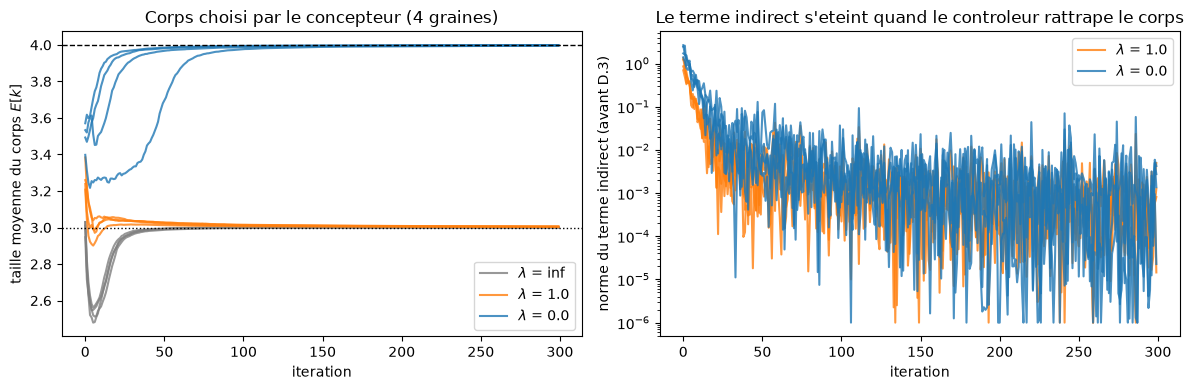

Norme du terme indirect (avant D.3), mediane sur les 4 graines :
  lambda = 10.0 : iteration 0 -> 0.190 | 25 -> 0.003 | 100 -> 0.0002 | 299 -> 0.0002
  lambda =  1.0 : iteration 0 -> 1.047 | 25 -> 0.008 | 100 -> 0.0032 | 299 -> 0.0010
  lambda =  0.0 : iteration 0 -> 2.093 | 25 -> 0.043 | 100 -> 0.0020 | 299 -> 0.0021


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lam, color in [(np.inf, "tab:gray"), (1.0, "tab:orange"), (0.0, "tab:blue")]:
    for i, s in enumerate(SEEDS):
        h = runs[lam][s]
        label = f"$\\lambda$ = {lam}" if i == 0 else None
        axes[0].plot(h[:, 0], color=color, alpha=0.8, label=label)
        if not np.isinf(lam):  # a lambda infini, le terme indirect est nul par construction
            axes[1].semilogy(np.maximum(h[:, 3], 1e-6), color=color, alpha=0.8, label=label)
axes[0].axhline(4, ls="--", color="k", lw=1)
axes[0].axhline(3, ls=":", color="k", lw=1)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("taille moyenne du corps $E[k]$")
axes[0].set_title("Corps choisi par le concepteur (4 graines)")
axes[0].legend()
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("norme du terme indirect (avant D.3)")
axes[1].set_title("Le terme indirect s'eteint quand le controleur rattrape le corps")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Norme du terme indirect (avant D.3), mediane sur les 4 graines :")
for lam in [10.0, 1.0, 0.0]:
    cols = [np.median([runs[lam][s][it, 3] for s in SEEDS]) for it in (0, 25, 100, 299)]
    print(f"  lambda = {lam:>4} : iteration 0 -> {cols[0]:.3f} | 25 -> {cols[1]:.3f} | 100 -> {cols[2]:.4f} | 299 -> {cols[3]:.4f}")

### Lecture du résultat

À gauche, les trajectoires de $\lambda = \infty$ plongent d'abord vers $E[k] \approx 2{,}5$ — la meilleure réponse du concepteur à un contrôleur réglé sur $w = 1$ est $k = 2$ (§3.1), et la politique reste à ce stade étalée entre $k = 2$ et $k = 3$, ce qui donne une moyenne autour de 2,5 sans que le corps soit fixé — puis remontent avec le contrôleur jusqu'à 3, atteint vers l'itération 50. Celles de $\lambda = 1$ partent de 3,2 à 3,4 et redescendent vers 3 dès la dizaine d'itérations, pour s'y stabiliser juste au-dessus (3,01 à 3,03). Celles de $\lambda = 0$ montent toutes à 4, l'une d'elles après un plateau vers 3,3 qui tient jusqu'à l'itération 30 environ, avant une montée rapide.

À droite et dans le tableau, le terme indirect est grand au début puis s'effondre. À $\lambda = 0$, sa norme médiane passe de 2,093 à l'itération 0 à 0,043 à l'itération 25 et à 0,002 ensuite. C'est le **théorème de l'enveloppe** : quand le contrôleur est à sa meilleure réponse, une petite variation de sa politique ne change plus l'objectif du concepteur au premier ordre, et le terme indirect s'annule. **Toute la différence entre les méthodes se joue donc dans les premières dizaines d'itérations**, tant que le contrôleur n'a pas encore rattrapé le corps.

## 4. Exercices

### Exercice 1 — Quand la Fisher n'est plus la hessienne

Avec $\sigma_F = 1$, la matrice de Fisher de la politique du suiveur vaut $1/\sigma_F^2 = 1$, exactement $-\partial^2_w J_F$. Le papier attribue l'avantage de la Fisher à sa semi-définie positivité (fig. 4c : 6000 contre 2500 pour la hessienne analytique). Ici les deux coïncident ; elles se séparent dès que $\sigma_F \neq 1$.

Refaites l'entraînement avec $\sigma_F = 0{,}5$ (la Fisher vaut alors 4, la hessienne reste $-1$) pour $\lambda \in \{0 ; 1 ; \infty\}$. Le terme indirect est-il plus petit ou plus grand ? Le concepteur sort-il encore du piège $k = 3$ ?

In [8]:
# TODO etudiant : modifier SIG_F (variable globale lue par follower_dist et exact_JF),
# relancer train_codesign pour lambda in {0.0, 1.0, np.inf} et les 4 graines,
# puis comparer E[k] final et l'iteration ou P(k=4) >= 0.9.
# Indice : remettre SIG_F = 1.0 a la fin pour ne pas fausser les cellules suivantes.
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 — Déplacer le piège

Le piège $k = 3$ dépend du coût de matériau. Pour $c = 0{,}2$, calculez avec `designer_value_fixed_controller` et `designer_value_adapted` les points fixes du jeu simultané et l'optimum de Stackelberg. Le gradient ordinaire reste-t-il piégé ? Vérifiez-le en relançant `train_codesign` pour $\lambda = \infty$ et $\lambda = 0$.

In [9]:
# TODO etudiant : changer COST, recalculer les points fixes (cf. section 3.1),
# puis relancer train_codesign pour lambda = np.inf et lambda = 0.0 sur les 4 graines.
# Indice : COST est lu par sample() et designer_value_fixed_controller().
print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 — Hessienne analytique contre Fisher

L'ablation de la fig. 4c du papier compare la Fisher à la hessienne analytique du surrogate, qui peut être indéfinie. Remplacez dans `train_codesign` le produit `fisher_vp` par un produit avec $-\nabla^2_w L_F$, la hessienne du surrogate PPO du suiveur estimée sur le lot (pensez à rajouter $\lambda$). Mesurez sur les 4 graines si l'apprentissage reste stable pour $\lambda = 0$.

In [10]:
# TODO etudiant : ecrire une variante de train_codesign ou fisher_vp(v) est remplace
# par un produit hessienne-vecteur sur -L_F (surrogate du suiveur, eq. 6),
# puis comparer E[k] final et la variance entre graines avec la version Fisher.
print("Exercice 3 a completer")

Exercice 3 a completer


## Conclusion

Ce carnet a confronté cinq affirmations du papier de Dai et al. à des mesures :

| Affirmation | Verdict ici |
|---|---|
| Le gradient du leader a un terme indirect (éq. 2-3) | **confirmé** : sur le duopole, il ramène exactement l'équilibre de Stackelberg (45 ; 22,5) de l'organe du dépôt |
| $\lambda$ interpole entre Stackelberg et le gradient ordinaire | **confirmé**, avec une précision : l'effet de $\lambda$ dépend de son rapport à la courbure du suiveur |
| Théorème 1 : estimateur par rapports de vraisemblance | **confirmé** : sans biais, erreur en $1/\sqrt{N}$, mais 40 % d'erreur à $N = 256$ |
| Stackelberg PPO bat le PPO ordinaire | **confirmé sur ce jouet** : 4 graines sur 4 sortent du piège $k = 3$ à $\lambda = 0$, 0 sur 4 en PPO ordinaire |
| Robustesse pour $\lambda \in [0{,}5 ; 10]$ | **non reproduit** : ici seul $\lambda \leq 0{,}5$ sort du piège, et $\lambda = 0$ est le meilleur réglage |

**L'écart sur $\lambda$ a une explication probable, que ce carnet ne teste pas.** Ici la politique du suiveur a un seul paramètre, sa courbure vaut 1, et la matrice de Fisher est exactement la hessienne : rien n'est mal conditionné, donc $\lambda = 0$ ne coûte rien et toute régularisation affaiblit le terme indirect (d'un facteur $1/(1 + \lambda)$). Dans le papier, la Fisher d'un réseau à des milliers de paramètres est mal conditionnée : $\lambda = 0$ devient instable, et $\lambda = 5$ reste petit devant ses grandes valeurs propres. C'est une hypothèse ; l'exercice 1 donne un moyen d'en tester une partie, en faisant varier la courbure par $\sigma_F$.

**Ce que le jouet ne montre pas** : le coût de calcul (le papier mesure +13 % de temps de calcul par rapport à BodyGen), l'horizon de plusieurs pas du leader qui construit le corps pièce par pièce (fig. 5c), et l'effet de la morphologie sur la dynamique, qui est le cœur des tâches MuJoCo.

**Suites possibles** : énoncer en Lean la condition du premier ordre du suiveur et la formule de la jacobienne implicite (éq. 3) pour le duopole, ce que le dépôt n'a pas encore ; ou reprendre le co-design avec un leader à plusieurs pas de construction, pour mesurer le compromis du papier sur l'horizon $T$.